**TP2 - MLP en TNG**

Dataset: 20 Newsgroups (~18.000 posts de foros de Usenet, clasificados en 20 categorías).


***Objetivos:***
* Partir del pipeline del TP1 (preprocesamiento configurable y TF-IDF) para entrenar un MLP en PyTorch.
* Buscar hiperparámetros con Optuna (con pruning): funciones de activación, 1 a 3 capas ocultas, neuronas por capa, optimizadores (SGD, RMSprop, Adam) con sus parámetros, y los hiperparámetros del TP1.
* Encontrar una configuración que sobreajuste y analizar performance y tiempos de todos los entrenamientos.

 **0. Setup**

In [1]:
!pip install -q mlflow optuna

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 55.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

**1. Datos: 20 Newsgroups**

In [2]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cuda


In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [4]:

newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


**2. Preprocesamiento configurable**

In [5]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)

In [6]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")

normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


**Análisis:**

El preprocesamiento usa la librería **NLTK** para tres tareas: tokenizar el texto *(word_tokenize)*, sacar palabras que no sirven para discriminar entre clases ya que aparecen en todos los textos *(stopwords.words("english"))* y normalizar cada token con *PorterStemmer* (recorta sufijos con reglas heurísticas) o *WordNetLemmatizer* (busca la forma de diccionario contra la base WordNet).

El pipeline es configurable a propósito: *remove_stopwords* y *normalization* son parámetros de la función, no decisiones fijas. Esto es lo que después Optuna explora como hiperparámetros de preprocesamiento, además de los de entrenamiento.

**3. Vectorización TF-IDF**

In [7]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [8]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])

Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


**Análisis:**

La vectorización usa *TfidfVectorizer* de **scikit-learn**. TF-IDF convierte cada documento en un vector donde cada dimensión es un término del vocabulario, ponderado por dos factores: qué tan frecuente es ese término en ese documento (TF) y qué tan poco frecuente es en el total de los documentos (IDF, inverso de la frecuencia en documentos).

El efecto práctico es que términos comunes a casi todos los documentos (como las stopwords) terminan con peso bajo automáticamente, y términos específicos de un tema pesan más. Es importante que el *fit* se haga solo sobre train y el *transform* se aplique igual sobre test. De esta manera, no se filtra información del test al vocabulario aprendido.

**4. Modelo: MLP**


In [9]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "tanh": nn.Tanh,
    "gelu": nn.GELU,
    "elu": nn.ELU,
    "leaky_relu": nn.LeakyReLU,
}

class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu"):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))
            layers.append(ACTIVATIONS[activation]())
            prev = h
        layers.append(nn.Linear(prev, num_classes))  # sin activación: salen logits
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [10]:
_m = MLP(input_dim=50, hidden_sizes=[32, 16], num_classes=20, activation="tanh")
_out = _m(torch.randn(4, 50))
assert _out.shape == (4, 20), "Revisá la clase MLP"
print(_m)
print("Parámetros:", sum(p.numel() for p in _m.parameters()))

MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): Tanh()
    (4): Linear(in_features=16, out_features=20, bias=True)
  )
)
Parámetros: 2500


**Análisis:**

Se implementó un MLP configurable en PyTorch con nn.Sequential: bloques Linear + activación y una última Linear sin activación, que devuelve logits (CrossEntropyLoss ya aplica el softmax). Sin activaciones no lineales, apilar capas lineales equivale a una sola capa lineal, es decir, al softmax del TP1.

**5. Entrenamiento (ya resuelto)**

In [11]:
%load_ext tensorboard

In [12]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)

    return history

In [13]:
import time

def train_model(model, train_loader, val_loader, optimizer, epochs, trial=None, verbose=False):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}

    for epoch in range(epochs):
        t0 = time.time()

        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(time.time() - t0)

        if verbose:
            print(f"Epoch {epoch+1}/{epochs} - train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
                  f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - {history['epoch_time'][-1]:.1f}s")

        if trial is not None:
            trial.report(val_acc, epoch)          # le cuenta a Optuna cómo va este trial
            if not np.isfinite(train_loss) or trial.should_prune():   # cortar si divergió o va mal
                trial.set_user_attr("history", history)
                raise optuna.TrialPruned()

    return history

**Análisis:**

train_model es el loop del TP1 con tres agregados: mide el tiempo de cada época, informa a Optuna el val_acc de cada época (trial.report) para que el pruner decida si cortar (trial.should_prune()), y corta si la loss diverge (NaN). Los historiales se guardan en user_attrs incluso en trials podados. Dentro de los trials no se usa MLflow, porque en el TP1 eso mezcló todas las métricas en un run implícito.

**6. Búsqueda de hiperparámetros con Optuna**

***Decisiones de diseño***

- “Momentos de orden 1 y 2”: los interpretamos como el promedio móvil de gradientes (orden 1: momentum de SGD, beta1 de Adam) y el promedio móvil de gradientes al cuadrado (orden 2: alpha de RMSprop, beta2 de Adam).

- Espacio de búsqueda: los 7 hiperparámetros del TP1 (stopwords, normalización, n-gramas, max_features, min_df, lr, batch_size) más activación (relu, tanh, gelu, elu, leaky_relu), 1 a 3 capas ocultas, 32 a 512 neuronas por capa, y optimizador (SGD, RMSprop, Adam) con sus parámetros y un lr con rango propio.

- Protocolo: split 80/20 del train para la búsqueda, test solo al final, máximo 10 épocas por trial. Cada trial devuelve el mejor val_acc entre épocas, y el entrenamiento final usa esa época.

- Pruning: MedianPruner con 10 trials de arranque y 2 épocas de calentamiento. El sampler TPE usa semilla fija.

- Overfitting: train_acc ≥ 0.95 y val_loss final ≥ 1.5 veces su mínimo.

In [14]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [15]:
def build_optimizer(trial, parameters):
    name = trial.suggest_categorical("optimizer", ["sgd", "rmsprop", "adam"])

    if name == "sgd":
        lr = trial.suggest_float("sgd_lr", 1e-2, 1.0, log=True)
        momentum = trial.suggest_float("sgd_momentum", 0.0, 0.99)       # momento de orden 1
        optimizer = optim.SGD(parameters, lr=lr, momentum=momentum)
    elif name == "rmsprop":
        lr = trial.suggest_float("rmsprop_lr", 1e-4, 1e-2, log=True)
        alpha = trial.suggest_float("rmsprop_alpha", 0.8, 0.999)        # momento de orden 2
        optimizer = optim.RMSprop(parameters, lr=lr, alpha=alpha)
    else:
        lr = trial.suggest_float("adam_lr", 1e-4, 1e-2, log=True)
        beta1 = trial.suggest_float("adam_beta1", 0.8, 0.99)            # momento de orden 1
        beta2 = trial.suggest_float("adam_beta2", 0.9, 0.9999)          # momento de orden 2
        optimizer = optim.Adam(parameters, lr=lr, betas=(beta1, beta2))

    trial.set_user_attr("lr", lr)   # columna única de lr para el análisis posterior
    return optimizer

In [16]:
MAX_EPOCHS = 10

def objective(trial):
    # --- HP del TP1: preprocesamiento, TF-IDF y batch size ---
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # --- Arquitectura (nuevo en el TP2) ---
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_sizes = [trial.suggest_categorical(f"units_l{i+1}", [32, 64, 128, 256, 512])
                    for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS.keys()))

    # --- Datos (split train/val igual que en el TP1) ---
    train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    # --- Modelo y optimizador ---
    model = MLP(X_tr.shape[1], hidden_sizes, NUM_CLASSES, activation).to(device)
    optimizer = build_optimizer(trial, model.parameters())
    trial.set_user_attr("n_params", sum(p.numel() for p in model.parameters()))

    # --- Entrenamiento (con pruning) ---
    start = time.time()
    try:
        history = train_model(model, train_loader, val_loader, optimizer,
                              epochs=MAX_EPOCHS, trial=trial)
    finally:
        trial.set_user_attr("train_time", time.time() - start)

    trial.set_user_attr("history", history)
    trial.set_user_attr("best_epoch", int(np.argmax(history["val_acc"])) + 1)
    return max(history["val_acc"])

In [17]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(
    study_name="mlp_20newsgroups",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=2),
    storage="sqlite:///optuna_tp2.db",
    load_if_exists=True,
)

N_TRIALS = 100
study.optimize(objective, n_trials=max(0, N_TRIALS - len(study.trials)),
               gc_after_trial=True, show_progress_bar=True)

  0%|          | 0/100 [00:00<?, ?it/s]

In [18]:
import pandas as pd

rows = []
for t in study.trials:
    if "history" not in t.user_attrs:
        continue
    h = t.user_attrs["history"]
    rows.append({
        "trial": t.number, "estado": t.state.name, "val_acc": t.value,
        "epocas": len(h["val_acc"]), "tiempo_train_s": t.user_attrs["train_time"],
        "n_params": t.user_attrs["n_params"], "optimizer": t.params["optimizer"],
        "lr": t.user_attrs["lr"], "activation": t.params["activation"],
        "n_layers": t.params["n_layers"], "batch_size": t.params["batch_size"],
        "max_features": t.params["max_features"],
    })
df = pd.DataFrame(rows)

print(df["estado"].value_counts(), "\n")
print(df[df["estado"] == "COMPLETE"].sort_values("val_acc", ascending=False).head(10).to_string(index=False))

estado
COMPLETE    51
PRUNED      49
Name: count, dtype: int64 

 trial   estado  val_acc  epocas  tiempo_train_s  n_params optimizer       lr activation  n_layers  batch_size  max_features
    26 COMPLETE 0.738842      10        4.215059   5130772   rmsprop 0.000498       gelu         1         128         10000
    68 COMPLETE 0.738400      10        6.194238   5130772   rmsprop 0.000452       tanh         1          64         10000
    21 COMPLETE 0.737958      10        4.156946   5130772   rmsprop 0.000511        elu         1         128         10000
    63 COMPLETE 0.737958      10        4.380399   5130772   rmsprop 0.000627       gelu         1         128         10000
    49 COMPLETE 0.737075      10        9.997091   5130772   rmsprop 0.001627 leaky_relu         1          32         10000
    97 COMPLETE 0.737075      10        4.415015   5130772   rmsprop 0.001264       gelu         1         128         10000
    67 COMPLETE 0.736191      10        5.043485    641364  

In [19]:
print("Mejores hiperparámetros:", study.best_params)

done = df[df["estado"] == "COMPLETE"].copy()
done["best_epoch"] = [study.trials[i].user_attrs["best_epoch"] for i in done["trial"]]
done["gap_train_val"] = [
    study.trials[i].user_attrs["history"]["train_acc"][-1] - study.trials[i].user_attrs["history"]["val_acc"][-1]
    for i in done["trial"]
]

def resumen(col):
    g = df.groupby(col).agg(trials=("trial", "count"), podados=("estado", lambda s: (s == "PRUNED").sum()))
    g["% podados"] = (100 * g["podados"] / g["trials"]).round(0)
    d = done.groupby(col).agg(val_acc_media=("val_acc", "mean"), val_acc_max=("val_acc", "max"),
                              tiempo_mediano_s=("tiempo_train_s", "median"))
    return g.join(d).round(3)

for col in ["optimizer", "activation", "n_layers", "batch_size", "max_features"]:
    print(f"--- por {col} ---")
    print(resumen(col).to_string(), "\n")

print("--- época del mejor val_acc (trials completos) ---")
print(done["best_epoch"].value_counts().sort_index().to_string())
print("Brecha train-val en la última época (media):", round(done["gap_train_val"].mean(), 3), "\n")

pr = df[df["estado"] == "PRUNED"].copy()
pr["t_sin_pruning"] = pr["tiempo_train_s"] / pr["epocas"] * MAX_EPOCHS
print("--- efecto del pruning ---")
print(f"Podados: {len(pr)} | épocas promedio antes de podar: {pr['epocas'].mean():.1f} de {MAX_EPOCHS}")
print(f"Tiempo de entrenamiento de los podados: {pr['tiempo_train_s'].sum():.0f}s "
      f"(sin pruning, estimado: {pr['t_sin_pruning'].sum():.0f}s)")
print(f"Tiempo de entrenamiento de toda la búsqueda: {df['tiempo_train_s'].sum():.0f}s")

Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 1, 'batch_size': 128, 'n_layers': 1, 'units_l1': 512, 'activation': 'gelu', 'optimizer': 'rmsprop', 'rmsprop_lr': 0.0004982760649352854, 'rmsprop_alpha': 0.9487436383900472}
--- por optimizer ---
           trials  podados  % podados  val_acc_media  val_acc_max  tiempo_mediano_s
optimizer                                                                          
adam            5        2       40.0          0.650        0.726             5.021
rmsprop        83       40       48.0          0.717        0.739             5.409
sgd            12        7       58.0          0.380        0.684             6.886 

--- por activation ---
            trials  podados  % podados  val_acc_media  val_acc_max  tiempo_mediano_s
activation                                                                          
elu             25       12       48.0          

**Análisis:**

El espacio de búsqueda es condicional: los parámetros de cada optimizador se sugieren solo si ese optimizador fue elegido. El MedianPruner corta un trial si su val_acc en una época es peor que la mediana de los trials anteriores en esa época. El estudio se guarda en SQLite para poder retomarlo.

**7. Entrenamiento final**

In [24]:
def optimizer_from_params(p, parameters):
    name = p["optimizer"]
    if name == "sgd":
        return optim.SGD(parameters, lr=p["sgd_lr"], momentum=p["sgd_momentum"])
    if name == "rmsprop":
        return optim.RMSprop(parameters, lr=p["rmsprop_lr"], alpha=p["rmsprop_alpha"])
    return optim.Adam(parameters, lr=p["adam_lr"], betas=(p["adam_beta1"], p["adam_beta2"]))

In [25]:
best = study.best_trial
bp = best.params


BEST_EPOCHS = best.user_attrs["best_epoch"]
BEST_HIDDEN = [bp[f"units_l{i+1}"] for i in range(bp["n_layers"])]
BEST_NGRAM = (1, 1) if bp["ngram_range"] == "1gram" else (1, 2)
BEST_LR = best.user_attrs["lr"]
print("Épocas del mejor trial:", BEST_EPOCHS, "| capas ocultas:", BEST_HIDDEN, "| lr:", round(BEST_LR, 5))

train_texts_final, test_texts_final = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, bp["max_features"], bp["min_df"]
)
train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target),
                                batch_size=bp["batch_size"], shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target),
                               batch_size=bp["batch_size"], shuffle=False)

torch.manual_seed(SEED)
model = MLP(X_train_final.shape[1], BEST_HIDDEN, NUM_CLASSES, bp["activation"]).to(device)
optimizer = optimizer_from_params(bp, model.parameters())
writer = SummaryWriter(log_dir="runs/mlp_final")

if mlflow.active_run():
    mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups")
with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params({**bp, "lr": BEST_LR, "epochs": BEST_EPOCHS})
    history_final = train_model(model, train_loader_final, test_loader_final, optimizer,
                                epochs=BEST_EPOCHS, verbose=True)
    for ep in range(BEST_EPOCHS):
        writer.add_scalars("loss", {"train": history_final["train_loss"][ep], "test": history_final["val_loss"][ep]}, ep)
        writer.add_scalars("accuracy", {"train": history_final["train_acc"][ep], "test": history_final["val_acc"][ep]}, ep)
        for nombre, clave in [("train_loss", "train_loss"), ("test_loss", "val_loss"),
                              ("train_acc", "train_acc"), ("test_acc", "val_acc")]:
            mlflow.log_metric(nombre, history_final[clave][ep], step=ep)
    sample_input, _ = next(iter(train_loader_final))
    mlflow.pytorch.log_model(model, "model", input_example=sample_input[:2].to(device), serialization_format="pickle")
writer.close()

print(f"Tiempo total de entrenamiento final: {sum(history_final['epoch_time']):.1f}s")

Épocas del mejor trial: 9 | capas ocultas: [512] | lr: 0.0005


2026/10/19 12:17:36 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 12:17:36 INFO mlflow.store.db.utils: Updating database tables
2026/10/19 12:17:39 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups' does not exist. Creating a new experiment.


Epoch 1/9 - train_loss: 2.7711 train_acc: 0.5199 - val_loss: 2.5139 val_acc: 0.5975 - 0.7s
Epoch 2/9 - train_loss: 2.0927 train_acc: 0.7081 - val_loss: 1.9324 val_acc: 0.6367 - 0.7s
Epoch 3/9 - train_loss: 1.4946 train_acc: 0.7643 - val_loss: 1.5346 val_acc: 0.6620 - 0.7s
Epoch 4/9 - train_loss: 1.1007 train_acc: 0.7985 - val_loss: 1.3113 val_acc: 0.6681 - 1.5s
Epoch 5/9 - train_loss: 0.8555 train_acc: 0.8251 - val_loss: 1.1930 val_acc: 0.6778 - 0.7s
Epoch 6/9 - train_loss: 0.6932 train_acc: 0.8528 - val_loss: 1.1310 val_acc: 0.6775 - 0.6s
Epoch 7/9 - train_loss: 0.5766 train_acc: 0.8763 - val_loss: 1.0983 val_acc: 0.6811 - 0.7s
Epoch 8/9 - train_loss: 0.4866 train_acc: 0.8963 - val_loss: 1.0837 val_acc: 0.6827 - 0.7s
Epoch 9/9 - train_loss: 0.4140 train_acc: 0.9131 - val_loss: 1.0820 val_acc: 0.6808 - 0.7s


2026/10/19 12:17:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/19 12:17:46 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/19 12:17:46 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/19 12:17:56 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label

Tiempo total de entrenamiento final: 6.9s


In [26]:
print(study.best_params)
print(study.best_value, "| trials:", len(study.trials))

{'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 1, 'batch_size': 128, 'n_layers': 1, 'units_l1': 512, 'activation': 'gelu', 'optimizer': 'rmsprop', 'rmsprop_lr': 0.0004982760649352854, 'rmsprop_alpha': 0.9487436383900472}
0.7388422448077773 | trials: 100


**Análisis:**

Se reentrenó la mejor configuración con todo el train durante 3 épocas, la del mejor val_acc de la búsqueda, y se evaluó una sola vez en test. MLflow registra parámetros, métricas y modelo, y TensorBoard las curvas. Los valores ‘val_’ que se imprimen aquí corresponden al conjunto de test y se pasan solo para graficar las curvas, las 3 épocas se eligieron con la validación de la búsqueda.

**8. Evaluación final**

In [27]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

Accuracy en test: 0.6808

                          precision    recall  f1-score   support

             alt.atheism       0.51      0.47      0.49       319
           comp.graphics       0.61      0.64      0.63       389
 comp.os.ms-windows.misc       0.64      0.58      0.61       394
comp.sys.ibm.pc.hardware       0.64      0.60      0.62       392
   comp.sys.mac.hardware       0.69      0.69      0.69       385
          comp.windows.x       0.79      0.67      0.72       395
            misc.forsale       0.78      0.78      0.78       390
               rec.autos       0.72      0.70      0.71       396
         rec.motorcycles       0.47      0.78      0.58       398
      rec.sport.baseball       0.90      0.80      0.85       397
        rec.sport.hockey       0.90      0.90      0.90       399
               sci.crypt       0.84      0.71      0.77       396
         sci.electronics       0.60      0.57      0.58       393
                 sci.med       0.78      0.77    

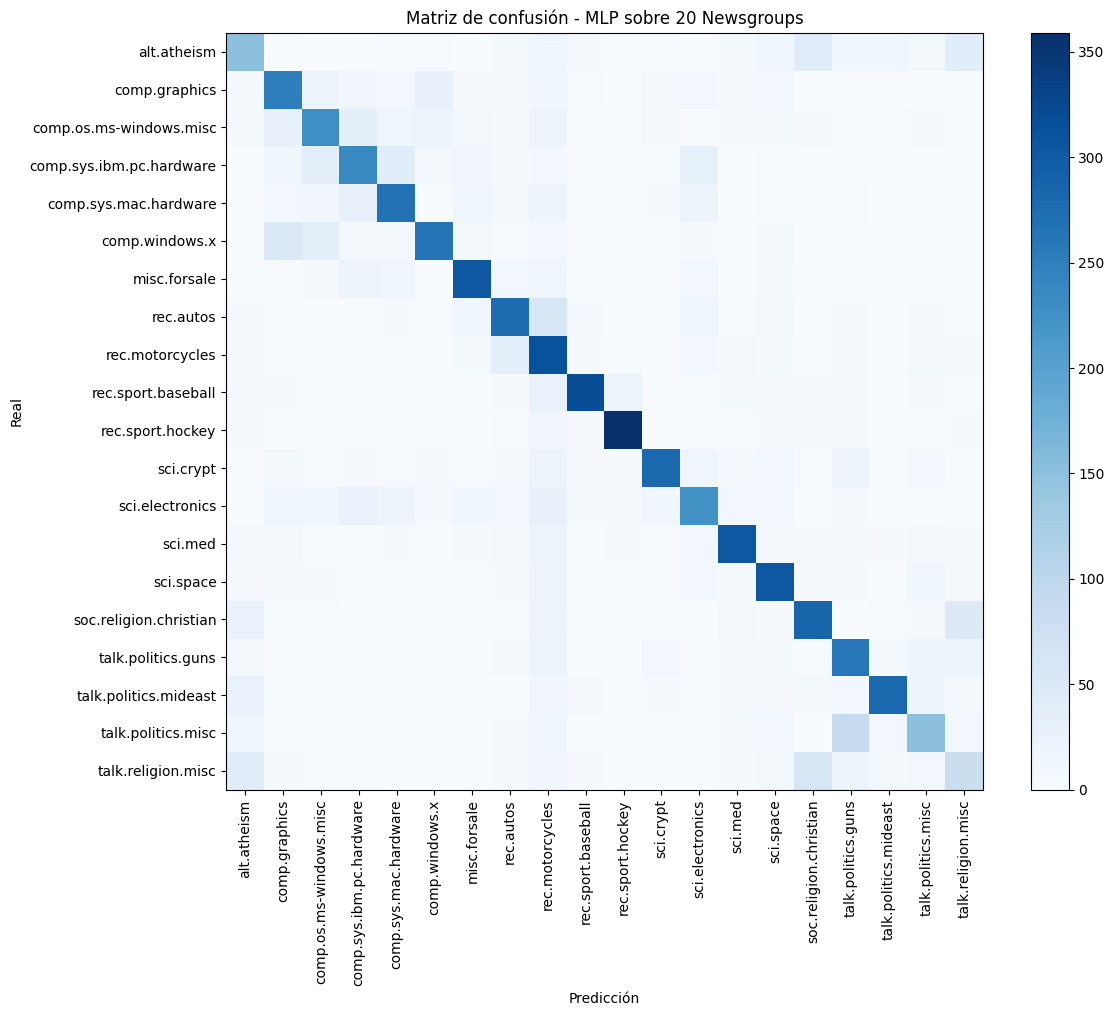

In [28]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - MLP sobre 20 Newsgroups")
plt.tight_layout()
plt.show()

**9. Experimento de Overfitting**

In [29]:
# --- Datos: mismo split train/val que en la búsqueda, con el preprocesamiento/TF-IDF del mejor trial ---
train_texts_best, _ = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
tr_texts, val_texts, tr_labels, val_labels = train_test_split(
    train_texts_best, newsgroups_train.target, test_size=0.2, random_state=SEED,
    stratify=newsgroups_train.target)
X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, BEST_NGRAM, bp["max_features"], bp["min_df"])
tr_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=bp["batch_size"], shuffle=True)
va_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=bp["batch_size"], shuffle=False)

SWEEP_EPOCHS = 30
depths = [1, 2, 3]
widths = [16, 64, 256, 1024]

def run_config(hidden_sizes):
    torch.manual_seed(SEED)
    m = MLP(X_tr.shape[1], hidden_sizes, NUM_CLASSES, bp["activation"]).to(device)
    opt = optimizer_from_params(bp, m.parameters())
    h = train_model(m, tr_loader, va_loader, opt, epochs=SWEEP_EPOCHS)
    return h, sum(p.numel() for p in m.parameters())

sweep = {}
configs = [("softmax (0 capas)", [])] + [(f"{d}x{w}", [w] * d) for d in depths for w in widths]
for name, hs in configs:
    h, n = run_config(hs)
    sweep[name] = {"hidden": hs, "history": h, "n_params": n}
    print(f"{name:18s} listo | params={n:>10,} | tiempo={sum(h['epoch_time']):.0f}s")

softmax (0 capas)  listo | params=   200,020 | tiempo=11s
1x16               listo | params=   160,356 | tiempo=11s
1x64               listo | params=   641,364 | tiempo=11s
1x256              listo | params= 2,565,396 | tiempo=18s
1x1024             listo | params=10,261,524 | tiempo=19s
2x16               listo | params=   160,628 | tiempo=11s
2x64               listo | params=   645,524 | tiempo=11s
2x256              listo | params= 2,631,188 | tiempo=12s
2x1024             listo | params=11,311,124 | tiempo=17s
3x16               listo | params=   160,900 | tiempo=12s
3x64               listo | params=   649,684 | tiempo=12s
3x256              listo | params= 2,696,980 | tiempo=13s
3x1024             listo | params=12,360,724 | tiempo=19s


In [30]:
# --- Tabla resumen con criterio explícito de overfitting ---
OVERFIT_TRAIN_ACC = 0.95    # train_acc final mínimo
OVERFIT_LOSS_RATIO = 1.5    # val_loss final respecto de su mínimo

rows = []
for name, r in sweep.items():
    h = r["history"]
    vl = np.array(h["val_loss"])
    rows.append({
        "config": name, "params": r["n_params"],
        "train_acc_final": h["train_acc"][-1], "val_acc_max": max(h["val_acc"]),
        "val_acc_final": h["val_acc"][-1], "ep_min_val_loss": int(vl.argmin()) + 1,
        "val_loss_min": vl.min(), "val_loss_final": vl[-1],
        "brecha_acc": h["train_acc"][-1] - h["val_acc"][-1],
        "tiempo_s": sum(h["epoch_time"]),
        "overfit": bool(h["train_acc"][-1] >= OVERFIT_TRAIN_ACC and vl[-1] > OVERFIT_LOSS_RATIO * vl.min()),
    })
sweep_df = pd.DataFrame(rows).round(3)
print(sweep_df.to_string(index=False))

           config   params  train_acc_final  val_acc_max  val_acc_final  ep_min_val_loss  val_loss_min  val_loss_final  brecha_acc  tiempo_s  overfit
softmax (0 capas)   200020            0.881        0.705          0.705               30         1.888           1.888       0.176    10.856    False
             1x16   160356            0.849        0.709          0.709               30         1.127           1.127       0.140    11.305    False
             1x64   641364            0.945        0.738          0.738               30         0.887           0.887       0.207    11.057    False
            1x256  2565396            0.971        0.738          0.721               17         0.880           1.008       0.249    17.840    False
           1x1024 10261524            0.972        0.741          0.701                8         0.880           1.380       0.271    19.322     True
             2x16   160628            0.859        0.653          0.648               30         1.2

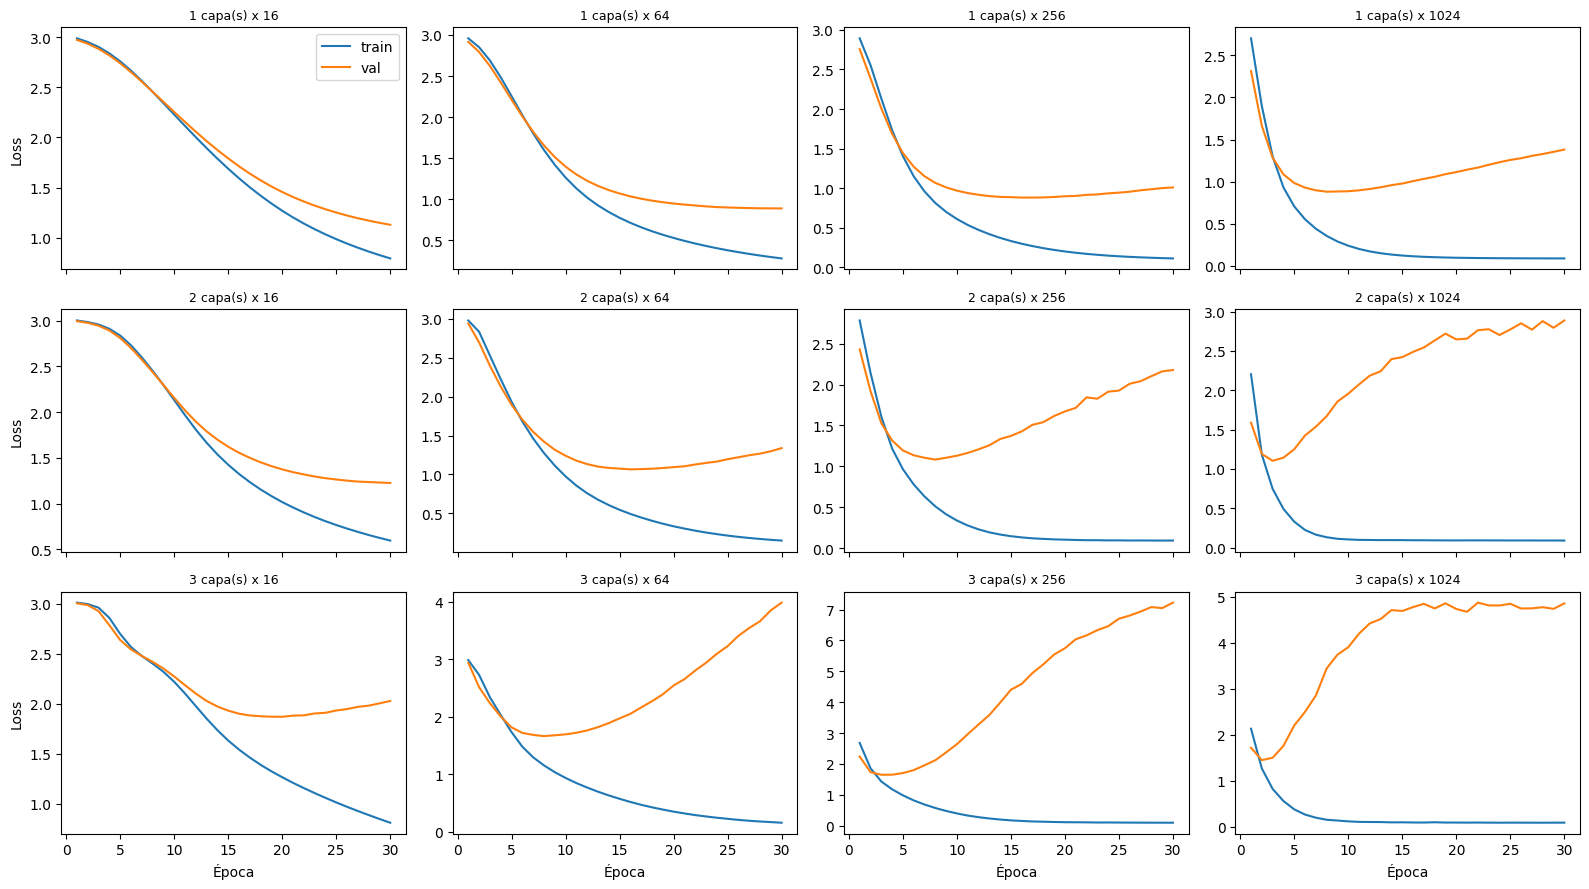

In [31]:
# --- Curvas train vs val de cada configuración ---
fig, axes = plt.subplots(len(depths), len(widths), figsize=(16, 9), sharex=True)
for i, d in enumerate(depths):
    for j, w in enumerate(widths):
        h = sweep[f"{d}x{w}"]["history"]
        ax = axes[i][j]
        ax.plot(range(1, SWEEP_EPOCHS + 1), h["train_loss"], label="train")
        ax.plot(range(1, SWEEP_EPOCHS + 1), h["val_loss"], label="val")
        ax.set_title(f"{d} capa(s) x {w}", fontsize=9)
        if i == len(depths) - 1:
            ax.set_xlabel("Época")
        if j == 0:
            ax.set_ylabel("Loss")
axes[0][0].legend()
plt.tight_layout()
plt.show()

In [32]:
print(f"Documentos de train con vector TF-IDF vacío: {(X_tr.getnnz(axis=1) == 0).mean():.2%}")

Documentos de train con vector TF-IDF vacío: 2.89%


In [33]:
torch.manual_seed(SEED)
m0 = MLP(X_train_final.shape[1], [], NUM_CLASSES, bp["activation"]).to(device)
opt0 = optimizer_from_params(bp, m0.parameters())
h0 = train_model(m0, train_loader_final, test_loader_final, opt0, epochs=30)
print(f"Softmax (0 capas, 30 épocas) - accuracy en test (última época): {h0['val_acc'][-1]:.4f}")

Softmax (0 capas, 30 épocas) - accuracy en test (última época): 0.6559


**Análisis:**

Sin pruning, fijamos la mejor configuración y variamos solo la capacidad: 0 capas (softmax) y 1 a 3 capas × 16, 64, 256 y 1024 neuronas, durante 30 épocas. El umbral inicial de train_acc (0.98) se recalibró a 0.95 al ver que todas las redes saturan en ~0.973, porque el 2.86% de los documentos de train tienen vector TF-IDF vacío.

**10. Figuras**

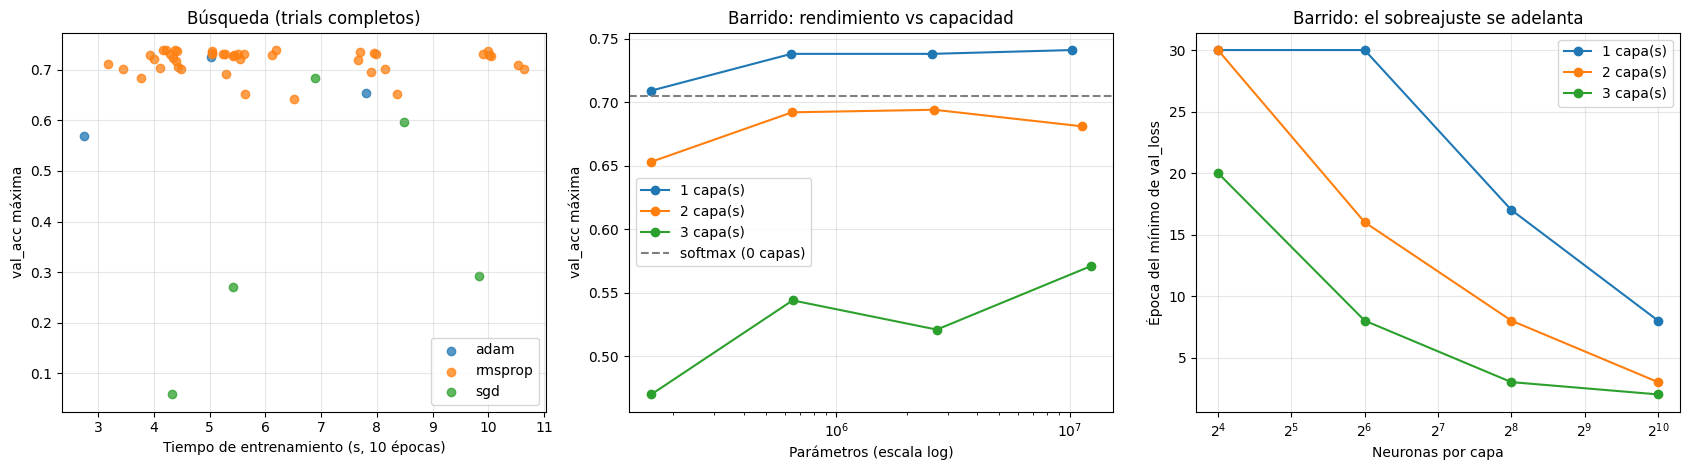

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (A) Búsqueda: val_acc vs tiempo de entrenamiento (solo trials completos)
ok = df[df["estado"] == "COMPLETE"]
for opt_name, g in ok.groupby("optimizer"):
    axes[0].scatter(g["tiempo_train_s"], g["val_acc"], label=opt_name, alpha=0.75)
axes[0].set_xlabel("Tiempo de entrenamiento (s, 10 épocas)")
axes[0].set_ylabel("val_acc máxima")
axes[0].set_title("Búsqueda (trials completos)")
axes[0].legend(); axes[0].grid(alpha=0.3)

# (B) Barrido: val_acc máxima vs parámetros, una línea por profundidad
sw = sweep_df[sweep_df["config"] != "softmax (0 capas)"].copy()
sw["depth"] = sw["config"].str.split("x").str[0].astype(int)
sw["width"] = sw["config"].str.split("x").str[1].astype(int)
for d, g in sw.groupby("depth"):
    axes[1].plot(g["params"], g["val_acc_max"], marker="o", label=f"{d} capa(s)")
base = sweep_df.loc[sweep_df["config"] == "softmax (0 capas)", "val_acc_max"].iloc[0]
axes[1].axhline(base, color="gray", linestyle="--", label="softmax (0 capas)")
axes[1].set_xscale("log")
axes[1].set_xlabel("Parámetros (escala log)"); axes[1].set_ylabel("val_acc máxima")
axes[1].set_title("Barrido: rendimiento vs capacidad")
axes[1].legend(); axes[1].grid(alpha=0.3)

# (C) Barrido: época del mínimo de val_loss vs ancho (cuándo empieza el sobreajuste)
for d, g in sw.groupby("depth"):
    axes[2].plot(g["width"], g["ep_min_val_loss"], marker="o", label=f"{d} capa(s)")
axes[2].set_xscale("log", base=2)
axes[2].set_xlabel("Neuronas por capa"); axes[2].set_ylabel("Época del mínimo de val_loss")
axes[2].set_title("Barrido: el sobreajuste se adelanta")
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

In [ ]:
print(f"Test con vector vacío: {(X_test_final.getnnz(axis=1) == 0).mean():.2%}")

**11. Análisis**

- ***Resultados de la búsqueda:*** De 100 trials, 63 se completaron y 37 se podaron. El mejor (val_acc 0.7556) usa 1 capa de 512 neuronas, tanh, Adam, batch_size 128 y 10.000 features. Los patrones más sólidos: 10.000 features (máximo 0.756 contra 0.654 con 2.000), Adam y RMSprop rinden parecido (0.756 y 0.749) y las cinco activaciones tienen máximos entre 0.746 y 0.756. Con ~2.263 documentos de validación el error de un accuracy es de ~0.9 puntos, así que no distinguimos activaciones. SGD rindió peor (mejor trial 0.683), pero con solo 9 trials y varias divergencias no concluimos que sea intrínsecamente peor.

- ***Pruning:*** Se podó el 37% de los trials, en promedio tras 3 de 10 épocas. Ahorró unos 124 s de entrenamiento (54 s contra ~178 s estimados), pero el reloj total fue de 746 s contra 389 s de entrenamiento: el resto es TF-IDF, conversión a tensores y overhead, que el pruning no reduce. El pruning pudo descartar redes profundas de arranque lento.

- ***Modelo final y comparación con el TP1:***
| Modelo | Épocas | Accuracy en test |
|---|---|---|
| Softmax del TP1 | 20 | 0.6569 |
| Softmax (0 capas) con los HP del TP2 | 30 | 0.6834 |
| MLP final (1 capa de 512, tanh) | 3 | 0.6977 |

  De los 4.1 puntos de mejora, unos 2.7 se deben a otros hiperparámetros y protocolo, y unos 1.4 a la capa oculta, una diferencia sugerente pero con una sola semilla. Las peores clases siguen siendo talk.religion.misc (f1 0.36), talk.politics.misc (0.49) y alt.atheism (0.55).

-  ***Overfitting:*** Todas las MLP salvo 1x16 cumplen el criterio. La época del mínimo de val_loss baja con el ancho (1 capa: 16, 8, 4, 2) y con la profundidad. La configuración claramente sobreajustada es 1x1024 (9.6M parámetros): val_loss mínima de 0.866 en la época 2 y 1.905 al final (×2.2), con val_acc de 0.742 a 0.701. Incluso 1x64, la mejor del barrido, sobreajusta desde la época 8, así que lo que la salva es la parada temprana. Los modelos aciertan todos los documentos no vacíos de train (prácticamente todos los documentos no vacíos).

- ***Tiempos y capacidad:*** Hasta 0.6M parámetros, 30 épocas tardan 10 s, dominadas por el overhead del DataLoader; con 10M o más suben a 16 o 18 s. El tiempo hasta el mínimo de val_loss baja con el ancho (~5.3 s en 1x16, ~1.1 s en 1x1024), pero ese mínimo no mejora (≈0.86 con 64 a 1024 neuronas): más capacidad compra velocidad, no precisión. A igual ancho, más capas empeoran el resultado, y todas las de 2 y 3 capas quedan por debajo del softmax.

- ***Limitaciones:*** Una sola semilla por configuración, ruido de ±0.9 puntos en validación, hiperparámetros elegidos con redes de 1 capa, pocos trials de SGD y posible sesgo del pruning contra redes profundas.